# Clustering Algorithms from Scratch

## Project Overview
This project implements two unsupervised learning algorithms from scratch:

- **K-Means**
- **DBSCAN**

The goal is to understand how clustering algorithms behave on datasets with different geometric structures.  
To evaluate the algorithms, the notebook uses four synthetic datasets:

- Blobs
- Anisotropic clusters
- Noisy Moons
- Noisy Circles

The project also compares the algorithms using:

- **F-Measure**
- **Normalized Mutual Information (NMI)**
- **Rand Score**

This notebook is designed as a clean, educational machine learning project suitable for GitHub.


In [1]:
from sklearn.datasets import make_blobs, make_moons, make_circles
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

## 1. Data Preparation

In this section, we generate four synthetic datasets that are commonly used to test clustering algorithms.  
These datasets help highlight the strengths and weaknesses of different clustering methods.


In [2]:
# number of samples
nsamp = 300
# random states based on our ID numbers [2040082 , 2042734 , 2140237 , 2140422]
rans = 72
# Blobs
blobs, y_true = make_blobs(n_samples=nsamp, random_state=rans)
y_true_blobs = y_true
# Anisotropic
X, y_true = make_blobs(n_samples=nsamp, random_state=rans)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
anisotropic = np.dot(X, transformation)
y_true_ani = y_true

# Noisy Moons
noisy_moons, y_true = make_moons(n_samples=nsamp, noise=0.1, random_state = rans)
y_true_moons = y_true
# Noisy Circles
noisy_circles, y_true = make_circles(n_samples=nsamp, factor=0.5, noise=0.05, random_state = rans)
y_true_circ = y_true
# Compiling all the data and labels into lists
ylabels= [y_true_blobs,y_true_ani,y_true_moons,y_true_circ ]
datasets = [blobs, anisotropic, noisy_moons, noisy_circles]

## 2. Visualizing the Original Datasets

Before applying the algorithms, we first inspect the structure of each dataset.


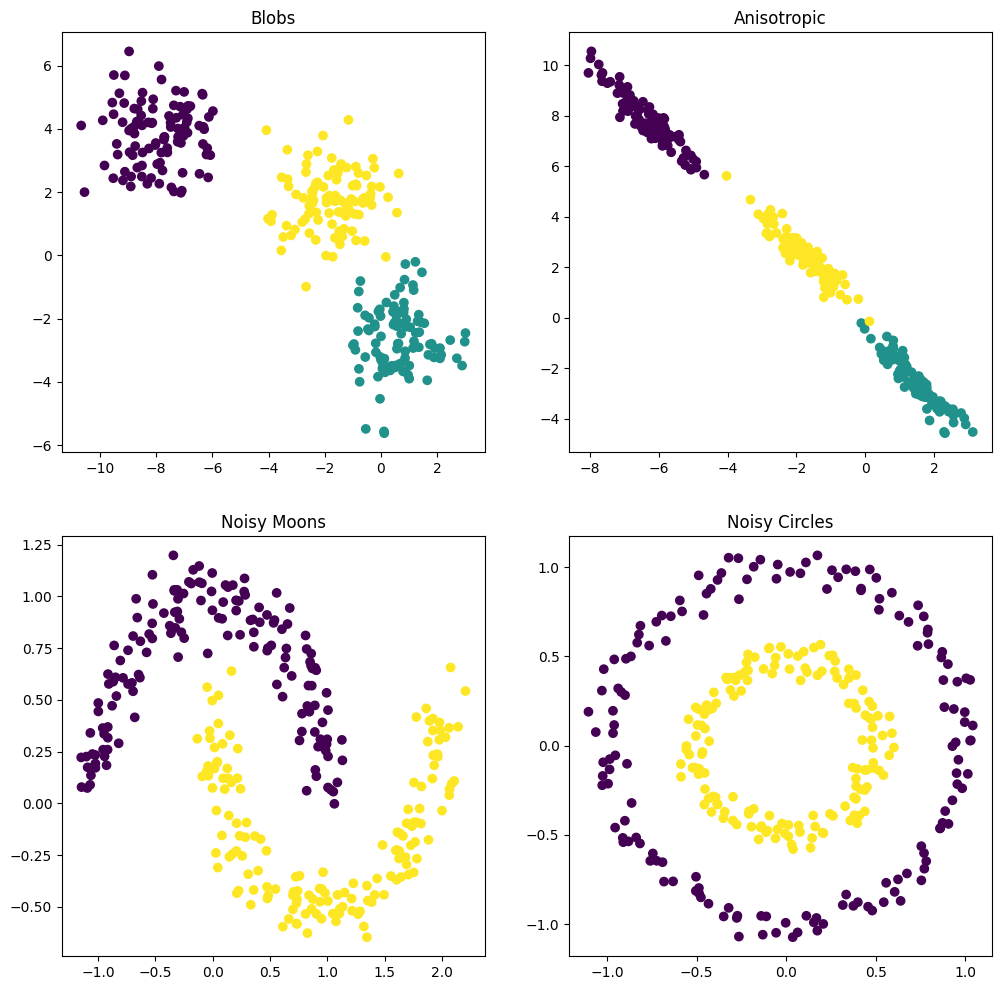

In [3]:
# Plotting the data with the correct labels
plt.figure(figsize=(12, 12))
titles = ['Blobs', 'Anisotropic', 'Noisy Moons', 'Noisy Circles']

for i, data in enumerate(datasets):
    plt.subplot(2, 2, i+1)
    plt.scatter(data[:, 0], data[:, 1], c=ylabels[i])
    plt.title(titles[i])

plt.show()

## 3. Implementing K-Means from Scratch

This section defines a custom implementation of the K-Means algorithm without relying on the built-in scikit-learn model.


In [4]:

class KMeans:

    def __init__(self, k=3):
        self.k = k  # Number of clusters
        self.centroids = None

    @staticmethod
    def ecl_distance(data_point, centroids):
        # Calculate Euclidean distance between a data point and all centroids
        return np.linalg.norm(centroids - data_point, axis=1)

    def fit(self, x, max_iterations=100):
        # Initialize centroids randomly within the range of the data
        self.centroids = np.random.uniform(np.amin(x, axis=0), np.amax(x, axis=0),
                                           size=(self.k, x.shape[1]))

        for _ in range(max_iterations):
            # Compute distances and assign each point to the nearest centroid
            distances = np.array([KMeans.ecl_distance(data_point, self.centroids) for data_point in x])
            clusters = np.argmin(distances, axis=1)

            # Update centroids as the mean of assigned data points,
            # with a check to avoid empty clusters
            new_centroids = np.array([np.mean(x[clusters == i], axis=0) if len(x[clusters == i]) > 0 else self.centroids[i] for i in range(self.k)])

            # Stop if centroids don't change much (convergence)
            if np.max(np.abs(self.centroids - new_centroids)) <= 1e-4:
                break
            else:
                self.centroids = new_centroids

        return clusters

    def predict(self, x):
        # Predict cluster for new data points based on distance to centroids
        distances = np.array([KMeans.ecl_distance(data_point, self.centroids) for data_point in x])
        return np.argmin(distances, axis=1)


## 4. Implementing DBSCAN from Scratch

This section defines a custom implementation of DBSCAN, a density-based clustering algorithm.


In [5]:
from sklearn.neighbors import KDTree
import numpy as np

class DBSCAN:
    def __init__(self, eps=0.5, minimum=5):
        """
        Initialize DBSCAN.
        """
        self.eps = eps
        self.minimum = minimum
        if eps <= 0 or minimum <= 0:
            raise ValueError("Epsilon and minimum must be > 0")

    def fit(self, X):
        """
        Apply DBSCAN to X.
        """
        if X.size == 0 or len(X) < self.minimum:
            raise ValueError("Dataset too small")

        labels = np.zeros(X.shape[0], dtype=int)  # Init labels
        cluster_id = 0  # Cluster ID
        tree = KDTree(X)  # KDTree

        for i in range(X.shape[0]):
            if labels[i] != 0:
                continue

            neighbors = self.neighbors(tree, X[i])
            if len(neighbors) < self.minimum:
                labels[i] = -1  # Noise
            else:
                cluster_id += 1
                self.expand_cluster(tree, X, labels, i, neighbors, cluster_id)

        return labels

    def expand_cluster(self, tree, X, labels, i, neighbors, cluster_id):
        """
        Expand cluster.
        """
        labels[i] = cluster_id
        j = 0
        while j < len(neighbors):
            neighbor = neighbors[j]

            if labels[neighbor] in [-1, 0]:
                labels[neighbor] = cluster_id
                new_neighbors = self.neighbors(tree, X[neighbor])

                if len(new_neighbors) >= self.minimum:
                    neighbors = np.append(neighbors, new_neighbors)

            j += 1

    def neighbors(self, tree, point):
        """
        Find neighbors.
        """
        return tree.query_radius([point], r=self.eps)[0]


## 5. Applying K-Means

We now apply the custom K-Means implementation to each dataset and visualize the clustering results.


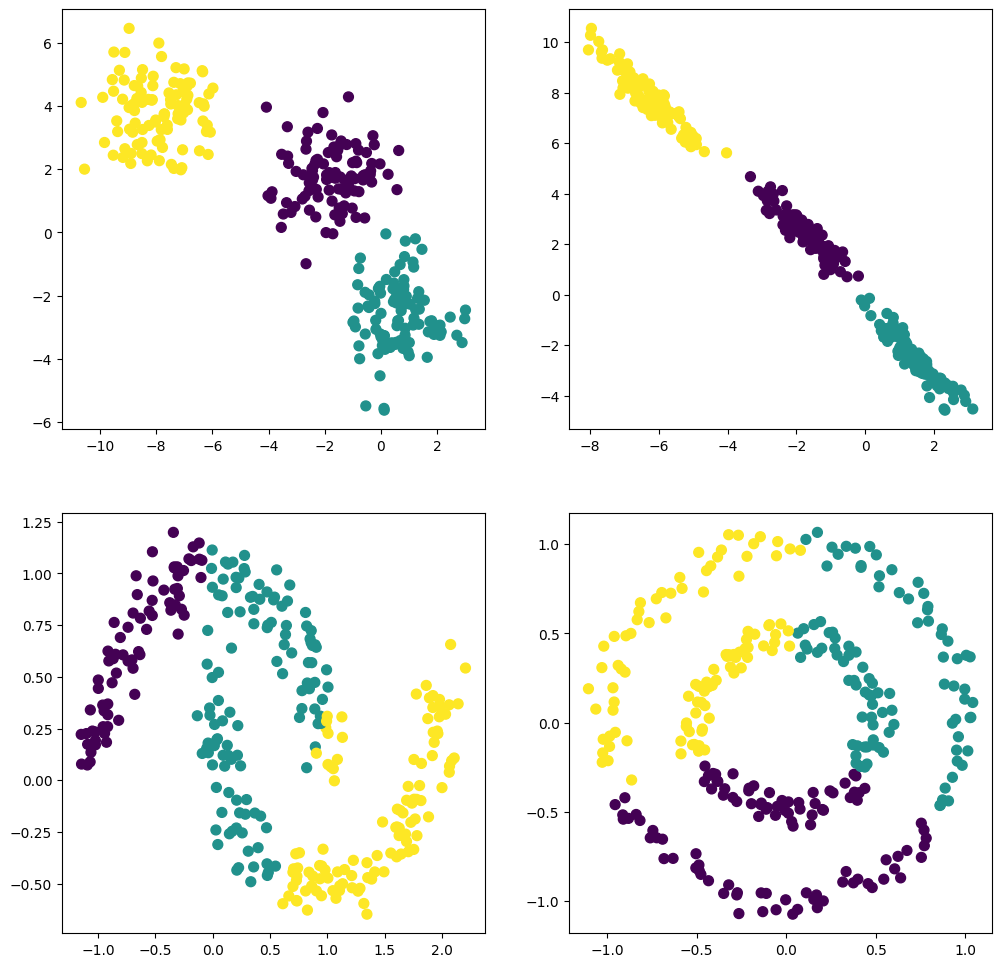

In [6]:

# Create a KMeans model with 3 clusters
kmeans = KMeans(k=3)

# Set up a 2x2 grid layout for plotting
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
axs = axs.ravel()

# Apply KMeans to each dataset and plot the results
#  datasets = [blobs, anisotropic, noisy_moons, noisy_circles]
#  ylabels= [y_true_blobs,y_true_ani,y_true_moons,y_true_circ ]

for i, dataset in enumerate(datasets):
    # Fit the model to the dataset
    kmeans.fit(dataset)
    # Predict cluster labels for each point in the dataset
    y_pred = kmeans.predict(dataset)

    # Plot the dataset with points colored by cluster labels
    axs[i].scatter(dataset[:, 0], dataset[:, 1], c=y_pred, s=50, cmap='viridis')

# Display the plots
plt.show()


## 6. Elbow Method for K-Means

The Elbow Method is used to estimate a suitable number of clusters for K-Means by examining inertia values.


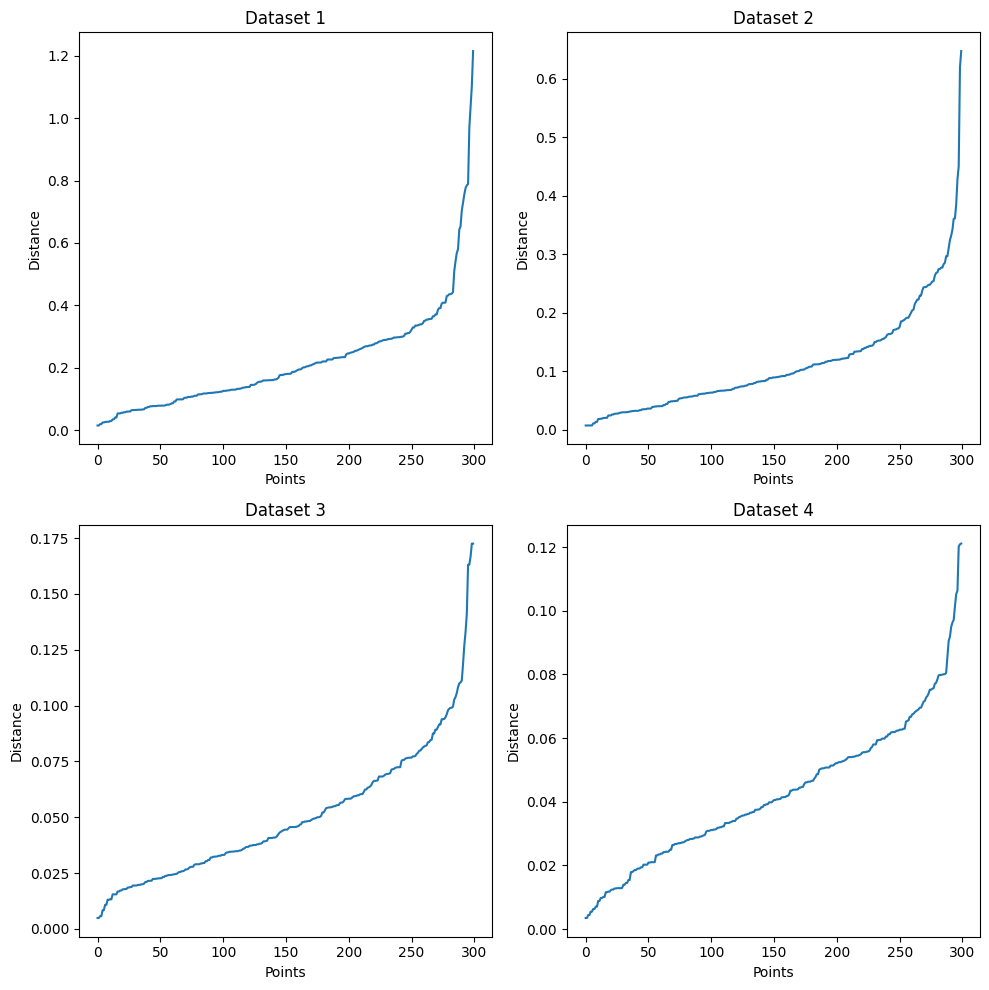

In [7]:
# Set up a 2x2 grid layout for plotting
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs = axs.ravel()

# Process each dataset to create elbow plots
for i, dataset in enumerate(datasets):
    # Use NearestNeighbors to find distances to the nearest point
    nearest_neighbors = NearestNeighbors(n_neighbors=2)
    neighbors = nearest_neighbors.fit(dataset)
    # Compute the distances and indices of the nearest neighbors
    distances, indices = neighbors.kneighbors(dataset)

    # Sort the distances
    distances = np.sort(distances[:, 1], axis=0)

    # Create an elbow plot for each dataset
    axs[i].plot(distances)
    # Set title, X-axis label, and Y-axis label for each plot
    axs[i].set_title(f'Dataset {i+1}')
    axs[i].set_xlabel('Points')
    axs[i].set_ylabel('Distance')

# Adjust the layout and display the plots
plt.tight_layout()
plt.show()

## 7. Applying DBSCAN

We now apply the custom DBSCAN implementation to the datasets and compare its behavior with K-Means.


/tmp/ipykernel_402/158347230.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i].legend()
/tmp/ipykernel_402/158347230.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i].legend()


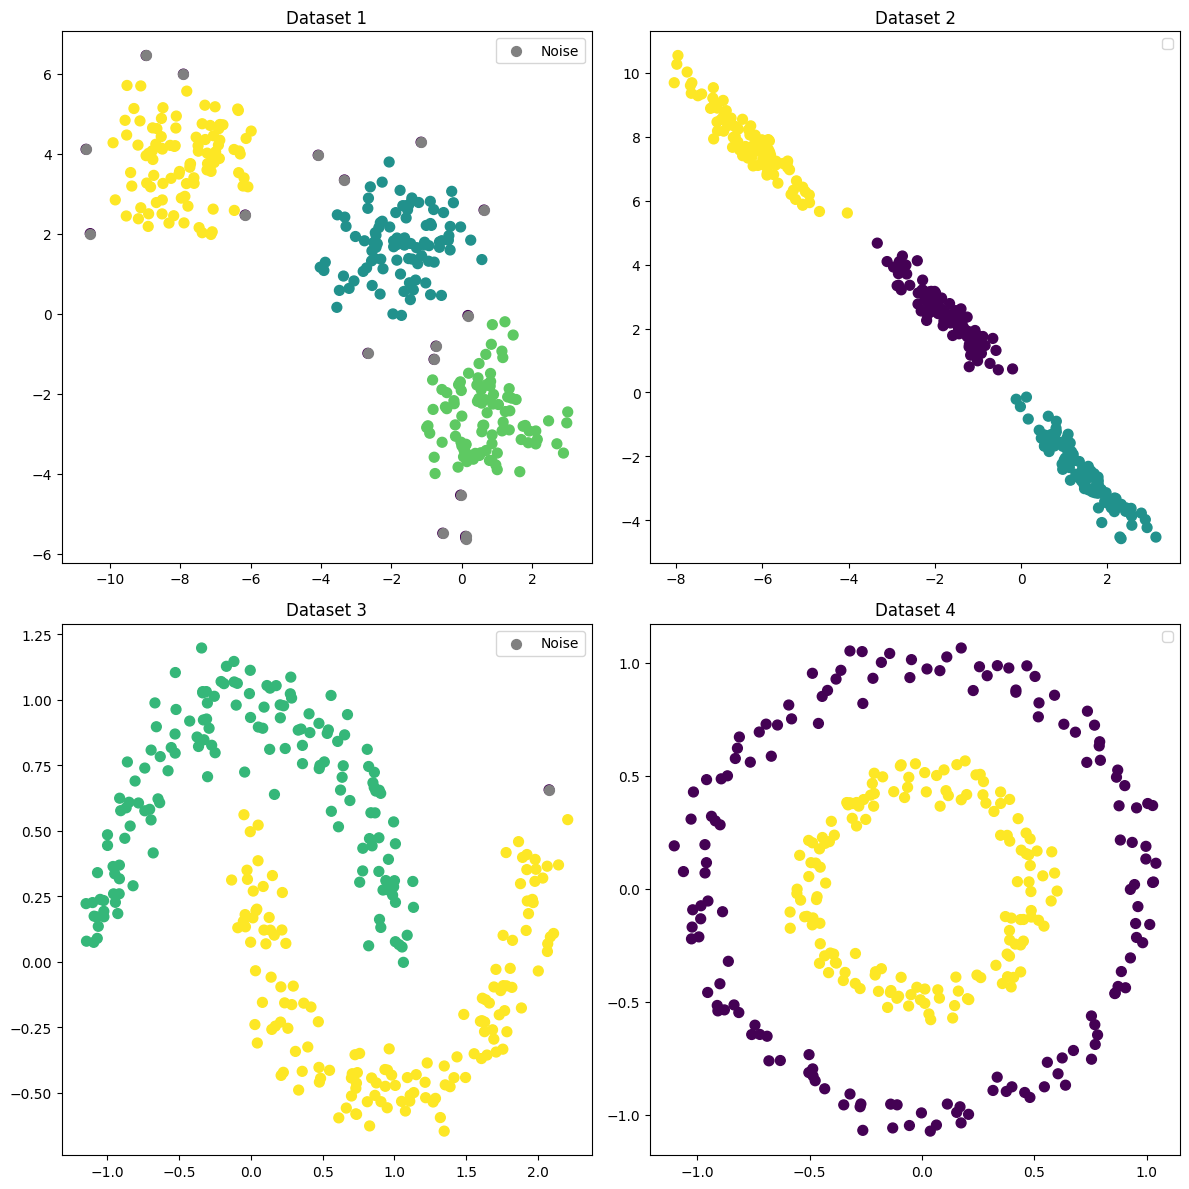

In [8]:
# Set up a 2x2 grid for plots
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
axs = axs.ravel()

eps_values = [0.7, 0.2]  # Epsilon values for DBSCAN

minimum_samples = 5  # Minimum samples for DBSCAN

# Apply DBSCAN to each dataset
for i, dataset in enumerate(datasets):
    # Choose eps value based on dataset index
    eps = eps_values[0] if i < 2 else eps_values[1]

    # Create and apply DBSCAN model
    dbscan_model = DBSCAN(eps=eps, minimum=minimum_samples)
    labels = dbscan_model.fit(dataset)

    # Plot points colored by cluster labels
    axs[i].scatter(dataset[:, 0], dataset[:, 1], c=labels, s=50, cmap='viridis')

    # Identify and mark noise points
    noise = np.where(labels == -1)[0]
    if len(noise) > 0:
        axs[i].scatter(dataset[noise, 0], dataset[noise, 1], c='gray', s=50, label='Noise')

    # Set titles and legends for each plot
    axs[i].set_title(f'Dataset {i+1}')
    axs[i].legend()

# Adjust layout and display plots
plt.tight_layout()
plt.show()

## 8. Evaluating Clustering Performance

The following sections compute evaluation metrics to compare the clustering quality of both algorithms.


In [9]:
# Initialize lists to store metrics for each dataset
kmeans_f_measure = []
kmeans_nmi = []
kmeans_rand = []

print("Performance Evaluation for KMeans")
for i, dataset in enumerate(datasets):
    # Fit the model once
    kmeans.fit(dataset)
    y_pred = kmeans.predict(dataset)

    # Calculate and append the metrics
    kmeans_f_measure.append(f1_score(ylabels[i], y_pred, average='macro'))
    kmeans_nmi.append(normalized_mutual_info_score(ylabels[i], y_pred))
    kmeans_rand.append(adjusted_rand_score(ylabels[i], y_pred))

    # Print the metrics for the current dataset
    print(f"\nDataset {i+1}:")
    print(f"F-measure: {kmeans_f_measure[-1]}")
    print(f"NMI Score: {kmeans_nmi[-1]}")
    print(f"Rand Score: {kmeans_rand[-1]}")

# Calculate the average of the metrics across all datasets
avg_kmeans_f_measure = np.mean(kmeans_f_measure)
avg_kmeans_nmi = np.mean(kmeans_nmi)
avg_kmeans_rand = np.mean(kmeans_rand)

# Print the average metrics
print("\nAverage Metrics for KMeans:")
print(f"Average F-measure: {avg_kmeans_f_measure}")
print(f"Average NMI Score: {avg_kmeans_nmi}")
print(f"Average Rand Score: {avg_kmeans_rand}")



Performance Evaluation for KMeans

Dataset 1:
F-measure: 0.3316582914572864
NMI Score: 0.9829929733076641
Rand Score: 0.9899831669528851

Dataset 2:
F-measure: 0.5503819650837681
NMI Score: 0.6565191143081133
Rand Score: 0.5417641805439577

Dataset 3:
F-measure: 0.16117216117216118
NMI Score: 0.32303923973937515
Rand Score: 0.25957183224251285

Dataset 4:
F-measure: 0.2740881710285897
NMI Score: 0.0007349888559001258
Rand Score: -0.0036255118859365764

Average Metrics for KMeans:
Average F-measure: 0.32932514718545136
Average NMI Score: 0.49082157905276314
Average Rand Score: 0.4469234169633548


In [10]:
# Initialize lists to store metrics
dbscan_f_measures = []
dbscan_nmi_scores = []
dbscan_rand_scores = []
eps_values = [0.7, 0.2]  # Epsilon values for DBSCAN
minimum_samples = 5


print("Performance Evaluation for DBSCAN")
for i, dataset in enumerate(datasets):
    # Fit the model once
    eps = eps_values[0] if i < 2 else eps_values[1]
    dbscan_model = DBSCAN(eps=eps, minimum=minimum_samples)
    labels = dbscan_model.fit(dataset)

    # Calculate and store all metrics
    dbscan_f_measures.append(f1_score(ylabels[i], labels, average='macro'))
    dbscan_nmi_scores.append(normalized_mutual_info_score(ylabels[i], labels))
    dbscan_rand_scores.append(adjusted_rand_score(ylabels[i], labels))

    print(f"\nDataset {i+1}:")
    print(f"F-measure: {dbscan_f_measures[-1]}")
    print(f"NMI Score: {dbscan_nmi_scores[-1]}")
    print(f"Rand Score: {dbscan_rand_scores[-1]}")

# Calculate the average of the metrics
avg_f_measure_dbscan = sum(dbscan_f_measures) / len(dbscan_f_measures)
avg_nmi_score_dbscan = sum(dbscan_nmi_scores) / len(dbscan_nmi_scores)
avg_rand_score_dbscan = sum(dbscan_rand_scores) / len(dbscan_rand_scores)

# Print the average metrics
print("\nAverage Metrics for DBSCAN:")
print(f"Average F-measure: {avg_f_measure_dbscan}")
print(f"Average NMI Score: {avg_nmi_score_dbscan}")
print(f"Average Rand Score: {avg_rand_score_dbscan}")


Performance Evaluation for DBSCAN

Dataset 1:
F-measure: 0.0
NMI Score: 0.8811818950832115
Rand Score: 0.9122288927748453

Dataset 2:
F-measure: 0.0024875621890547263
NMI Score: 0.966000234160485
Rand Score: 0.9800173492833615

Dataset 3:
F-measure: 0.0016611295681063123
NMI Score: 0.9572822987380829
Rand Score: 0.980066229639934

Dataset 4:
F-measure: 0.0
NMI Score: 1.0
Rand Score: 1.0

Average Metrics for DBSCAN:
Average F-measure: 0.0010371729392902596
Average NMI Score: 0.9511161069954448
Average Rand Score: 0.9680781179245352


## 9. Summary Comparison of All Algorithms

This section aggregates the evaluation metrics and presents a high-level comparison between K-Means and DBSCAN.


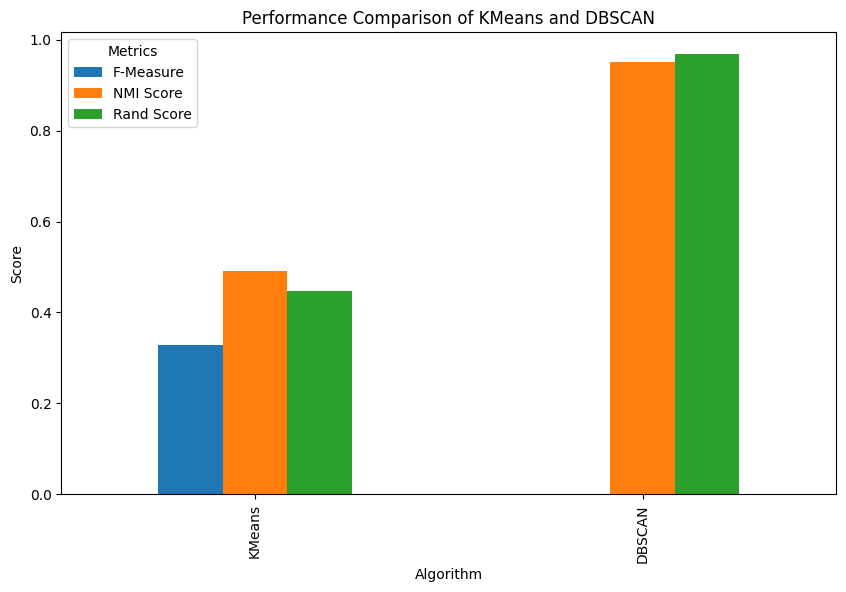

In [11]:
# Organizing data for each algorithm into a dictionary
data = {
    'Algorithm': ['KMeans', 'DBSCAN'],
    'F-Measure': [avg_kmeans_f_measure, avg_f_measure_dbscan],
    'NMI Score': [avg_kmeans_nmi, avg_nmi_score_dbscan],
    'Rand Score': [avg_kmeans_rand, avg_rand_score_dbscan]
}

# Creating a DataFrame from the data
results_df = pd.DataFrame(data)

# Plotting the data
results_df.set_index('Algorithm').plot(kind='bar', figsize=(10, 6))
# Adding title, labels, and legend to the plot
plt.title('Performance Comparison of KMeans and DBSCAN')
plt.ylabel('Score')
plt.xlabel('Algorithm')
plt.legend(title='Metrics')
# Displaying the plot
plt.show()


## 10. Final Visualization of All Clustering Results

The final figure shows the clustering output of both algorithms across all datasets side by side.


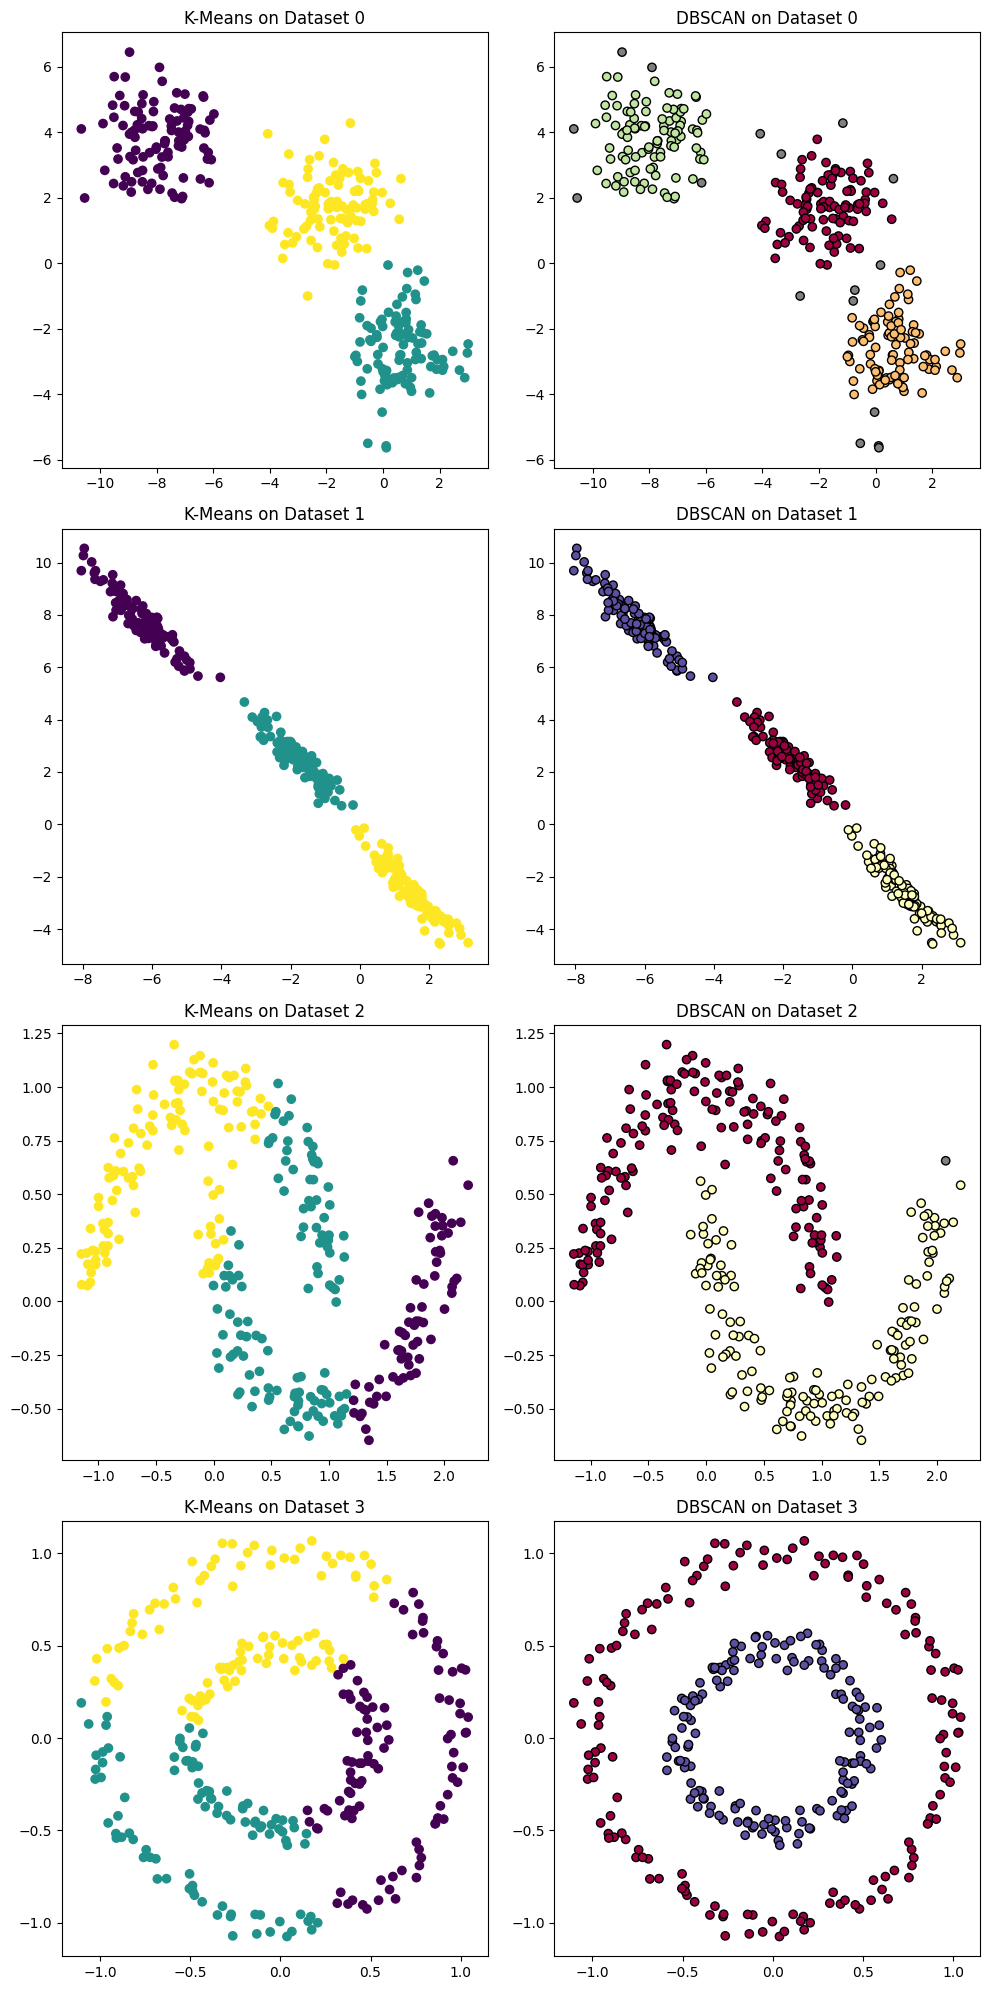

In [12]:
# Create a subplot grid based on the number of datasets, with two columns
fig, axs = plt.subplots(len(datasets), 2, figsize=(10, 20))

# Titles for each column
titles = ['K-Means', 'DBSCAN']

# Loop through each dataset
for i, dataset in enumerate(datasets):
    eps = eps_values[0] if i < 2 else eps_values[1]
    dbscan_model = DBSCAN(eps=eps, minimum=minimum_samples)
    # Apply K-Means algorithm
    c_y_pred = kmeans.fit(dataset)
    # Plot the results of K-Means
    axs[i, 0].scatter(dataset[:, 0], dataset[:, 1], c=c_y_pred)
    axs[i, 0].set_title(f'{titles[0]} on Dataset {i}')

    # Apply DBSCAN algorithm
    c_labels = dbscan_model.fit(dataset)
    # Generate a list of colors using the Spectral color map
    unique_labels = list(set(c_labels))  # Convert set to list
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

    # Assign colors to points, using grey for noise
    point_colors = ['grey' if label == -1 else colors[unique_labels.index(label)] for label in c_labels]

    # Plot the results of DBSCAN
    axs[i, 1].scatter(dataset[:, 0], dataset[:, 1], c=point_colors, edgecolor='k')
    axs[i, 1].set_title(f'{titles[1]} on Dataset {i}')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()


## 11. Conclusion

This project demonstrates the practical differences between two important clustering algorithms:

- **K-Means** works well when clusters are compact and roughly spherical.
- **DBSCAN** is more flexible for irregular shapes and can detect noise points.

By implementing both algorithms from scratch, this notebook highlights not only how clustering works in theory, but also how dataset shape affects algorithm performance in practice.

### Possible Improvements
- Tune DBSCAN parameters more systematically
- Add silhouette score analysis
- Compare with scikit-learn implementations
- Test on real-world datasets in addition to synthetic data
